# Etapa 2 — Parte 2: Distribuições temporais

Este notebook é a superfície executável da Parte 2. Ele explica cada etapa em ordem, chama as funções científicas reutilizáveis do pacote Python, publica a execução canônica, mostra tabelas e gráficos e valida a reprodução dos artefatos.

A unidade observacional é um vídeo validado por linha. Frames são medidas internas do vídeo e não observações independentes. V-LIBRASIL e MINDS-Libras permanecem como populações descritivas separadas.

Limites desta etapa: sem Parte 3, inferência, remoção de outliers, imputação, balanceamento, splits, treinamento, alteração de manifests ou execução de ffprobe.

## 1. Confirmar autorização e preparar o ambiente

Nesta etapa confirmamos que a execução autorizada é somente a Parte 2 — Distribuições temporais. O código de análise fica no módulo Python; este notebook orquestra a execução e exibe os resultados.

### 1.1 O que será feito

1. Carregar os contratos e os manifests canônicos.
2. Executar os testes relevantes antes da publicação.
3. Calcular estatísticas temporais e candidatos extremos sem excluir linhas.
4. Gerar tabelas, histogramas, boxplots e ECDFs separadamente por dataset.
5. Publicar atomicamente a execução e conferir hashes, determinismo e correspondência dos outputs.

### 1.2 O que não será feito

Não haverá análise de classes da Parte 3, testes inferenciais, interpretação causal ou decisão sobre remoção de observações.

In [1]:
from pathlib import Path
import subprocess
import sys
from tempfile import TemporaryDirectory

import pandas as pd
from IPython.display import Image, Markdown, display

APP_ROOT = Path.cwd()
while not (APP_ROOT / 'dataset' / 'src').is_dir() and APP_ROOT != APP_ROOT.parent:
    APP_ROOT = APP_ROOT.parent
assert (APP_ROOT / 'dataset' / 'src').is_dir(), f'Raiz do app não encontrada a partir de {Path.cwd()}'
sys.path.insert(0, str(APP_ROOT / 'dataset' / 'src'))

from libras_translation.analysis import (
    DATASET_CONTRACTS,
    TEMPORAL_FIELDS,
    analyze_temporal_distributions,
    load_published_part2,
    load_validated_manifest,
    render_temporal_figures,
    run_part2,
)
from libras_translation.analysis.dataset_profile import canonical_manifest_path, sha256_file

EDA_ROOT = APP_ROOT / 'data' / 'processed' / 'eda'
print('APP_ROOT:', APP_ROOT)
print('EDA_ROOT:', EDA_ROOT)
print('Datasets:', tuple(DATASET_CONTRACTS))
print('Temporal fields:', TEMPORAL_FIELDS)

APP_ROOT: c:\Users\mdbaa\development\Dissertacao\app
EDA_ROOT: c:\Users\mdbaa\development\Dissertacao\app\data\processed\eda
Datasets: ('v-librasil-raw', 'minds-libras-raw')
Temporal fields: ('actual_frame_count', 'actual_duration', 'actual_fps')


## 2. Executar os testes e publicar a execução canônica

### 2.1 Testes antes da análise

Os testes de contratos, caracterização e distribuições são executados dentro do notebook. Se algum teste falhar, a célula interrompe o fluxo antes da publicação.

### 2.2 Execução da Parte 2

A função reutilizável run_part2 carrega exclusivamente os manifests validados, calcula as tabelas, gera os gráficos, valida a publicação e atualiza CURRENT.json somente depois da validação. Esta chamada é feita pelo notebook para que a execução fique explícita e reproduzível nesta superfície.

In [2]:
test_command = [
    sys.executable,
    '-m',
    'unittest',
    'discover',
    '-s',
    'dataset/tests',
    '-p',
    'test_*.py',
    '-v',
]
test_process = subprocess.run(test_command, cwd=APP_ROOT, capture_output=True, text=True)
print(test_process.stdout[-4000:])
if test_process.returncode != 0:
    print(test_process.stderr[-4000:])
    raise RuntimeError('Os testes relevantes falharam; a publicação foi interrompida.')

test_results = {
    'status': 'passed',
    'command': ' '.join(test_command),
    'output_tail': test_process.stdout[-2000:],
}
run_result = run_part2(test_results=test_results)
print('run_id:', run_result['run_id'])
print('decision:', run_result['decision'])
display(pd.DataFrame(run_result['validation']['observations']).T)
assert run_result['validation']['all_passed'] is True


run_id: 20261106T032703445089Z-78a34e7
decision: COMPLETE WITH NOTES


,expected,observed,one_row_per_video
v-librasil-raw,4086,4086,True
minds-libras-raw,800,800,True


## 3. Ler a proveniência e confirmar o baseline

### 3.1 Identificação da execução

Agora lemos CURRENT.json e provenance/execution.json publicados pela execução. O notebook não digita manualmente run_id, SHA-256, tamanhos ou contagens: esses valores são lidos dos artefatos produzidos pela execução.

### 3.2 Resumo da Parte 1 aprovada

O overview da Parte 1 é exibido como contexto. Ele não é reinterpretado nem usado para misturar os datasets.

In [3]:
published = load_published_part2(EDA_ROOT)
current = published['current']
execution = published['execution']
assert current['stage'] == 'stage2_part2_temporal_distributions'
assert execution['validation']['all_passed'] is True

print('Current run:', current['run_id'])
print('Decision:', current['decision'])
print('Historical Part 1 run:', execution['baseline_part1'].get('run_id'))
display(pd.DataFrame(execution['inputs'])[['dataset', 'sha256', 'size_bytes', 'row_count']])

part1_overview = pd.read_csv(EDA_ROOT / 'tables' / 'dataset_overview.csv')
display(part1_overview)
expected_rows = {contract.expected_rows for contract in DATASET_CONTRACTS.values()}
assert set(part1_overview['videos']) >= expected_rows
assert current['figures']

Current run: 20261106T032703445089Z-78a34e7
Decision: COMPLETE WITH NOTES
Historical Part 1 run: 20261106T031725199354Z-78a34e7


,dataset,sha256,size_bytes,row_count
0,v-librasil-raw,f0a2259e6094409a59f0f02a77eee478a91967fcc928a6...,392028,4086
1,minds-libras-raw,913c4c185ef4fae21bfded0a78c4c8360a31f2cba51284...,44397,800


,dataset,videos,classes_unique,signers_unique,class_user_combinations_unique,codecs_unique,resolutions_unique,actual_fps_unique,physical_key_column,manifest_key_column,fps_semantics,exception_count_outside_corpus
0,v-librasil-raw,4086,1364,3,4086,1,3,6,filesystem_key,filesystem_key,frame_count,3
1,minds-libras-raw,800,20,8,160,1,1,172,video_id,filesystem_key,frame_count,0


## 4. Carregar os manifests canônicos e calcular as tabelas

### 4.1 Leitura das entradas

Cada dataset é carregado por load_validated_manifest, que valida schema, chave física, validade e número esperado de linhas. Nenhuma linha é filtrada e nenhuma coluna é sobrescrita.

### 4.2 Estatísticas temporais

A função analyze_temporal_distributions produz estatísticas na escala original, percentis adicionais e candidatos IQR. actual_fps permanece numérico e não é transformado em categorias.

In [4]:
frames = {dataset: load_validated_manifest(dataset) for dataset in DATASET_CONTRACTS}
for dataset, frame in frames.items():
    identity = next(item for item in execution['inputs'] if item['dataset'] == dataset)
    assert len(frame) == DATASET_CONTRACTS[dataset].expected_rows
    assert frame[DATASET_CONTRACTS[dataset].physical_key_column].nunique() == len(frame)
    assert sha256_file(canonical_manifest_path(dataset)) == identity['sha256']
    print(dataset, 'rows=', len(frame), 'columns=', len(frame.columns))

analysis = analyze_temporal_distributions(frames)
temporal_stats = analysis['temporal_distribution_statistics']
temporal_percentiles = analysis['temporal_percentiles']
display(temporal_stats)
display(temporal_percentiles)
assert set(temporal_stats['variable']) == set(TEMPORAL_FIELDS)
assert set(temporal_percentiles['variable']) == set(TEMPORAL_FIELDS)

v-librasil-raw rows= 4086 columns= 29
minds-libras-raw rows= 800 columns= 30


,dataset,variable,unit,denominator,n,missing_real,mean,median,std_ddof_1,min,...,mad,skewness_fisher_pearson,coefficient_of_variation,p05_minus_median,p95_minus_median,iqr_lower_fence,iqr_upper_fence,below_iqr_lower_fence,above_iqr_upper_fence,extreme_criterion
0,v-librasil-raw,actual_frame_count,frames,4086,4086,0,216.205825,181.000000,96.437878,46.000000,...,43.000000,1.665954,0.446047,62.000000,217.000000,-30.500000,445.500000,0,102,IQR fences: value < Q1 - 1.5*IQR or value > Q3...
1,v-librasil-raw,actual_duration,s,4086,4086,0,5.724900,5.373000,1.835709,1.469000,...,0.799833,2.732129,0.320653,1.588000,3.527500,2.218882,8.758751,18,221,IQR fences: value < Q1 - 1.5*IQR or value > Q3...
2,v-librasil-raw,actual_fps,frames/s,4086,4086,0,38.213736,29.970030,13.502702,23.976024,...,0.000000,0.982170,0.353347,0.000000,30.029970,-14.985015,104.895105,0,0,IQR fences: value < Q1 - 1.5*IQR or value > Q3...
3,minds-libras-raw,actual_frame_count,frames,800,800,0,137.066250,137.000000,26.519728,71.000000,...,18.000000,0.212240,0.193481,42.050000,44.050000,62.500000,210.500000,0,2,IQR fences: value < Q1 - 1.5*IQR or value > Q3...
4,minds-libras-raw,actual_duration,s,800,800,0,4.536364,4.534000,0.883679,2.336000,...,0.600000,0.212531,0.194799,1.401700,1.467700,2.059000,6.979000,0,2,IQR fences: value < Q1 - 1.5*IQR or value > Q3...
5,minds-libras-raw,actual_fps,frames/s,800,800,0,30.225627,30.217391,0.045480,30.129310,...,0.027518,0.837842,0.001505,0.053457,0.095109,30.108871,30.334677,0,22,IQR fences: value < Q1 - 1.5*IQR or value > Q3...


,dataset,variable,unit,denominator,n,missing_real,p05,p10,q1,median,q3,p90,p95,p99
0,v-librasil-raw,actual_frame_count,frames,4086,4086,0,119.000000,130.000000,148.000000,181.000000,267.00000,349.00000,398.0000,535.150000
1,v-librasil-raw,actual_duration,s,4086,4086,0,3.785000,4.119000,4.671333,5.373000,6.30630,7.56250,8.9005,12.954500
2,v-librasil-raw,actual_fps,frames/s,4086,4086,0,29.970030,29.970030,29.970030,29.970030,59.94006,59.94006,60.0000,60.000000
3,minds-libras-raw,actual_frame_count,frames,800,800,0,94.950000,102.000000,118.000000,137.000000,155.00000,169.00000,181.0500,201.000000
4,minds-libras-raw,actual_duration,s,800,800,0,3.132300,3.367000,3.904000,4.534000,5.13400,5.60060,6.0017,6.667000
5,minds-libras-raw,actual_fps,frames/s,800,800,0,30.163934,30.176367,30.193548,30.217391,30.25000,30.28910,30.3125,30.348837


## 5. Identificar candidatos a valores extremos

### 5.1 Regra utilizada

Um candidato é uma observação abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR. Essa regra apenas sinaliza a posição extrema na distribuição. Ela não classifica o vídeo como inválido e não remove nenhuma linha.

### 5.2 Exibição

A tabela completa é mostrada com dataset, chave física, classe, sinalizador, variável, valor, critério e flag.

In [5]:
temporal_candidates = analysis['temporal_extreme_candidates']
candidate_counts = (
    temporal_candidates.groupby(['dataset', 'variable', 'flag'], dropna=False, sort=True)
    .size()
    .rename('count')
    .reset_index()
)
display(candidate_counts)
display(temporal_candidates)
print('Total de candidatos sinalizados:', len(temporal_candidates))

,dataset,variable,flag,count
0,minds-libras-raw,actual_duration,above_iqr_upper_fence,2
1,minds-libras-raw,actual_fps,above_iqr_upper_fence,22
2,minds-libras-raw,actual_frame_count,above_iqr_upper_fence,2
3,v-librasil-raw,actual_duration,above_iqr_upper_fence,221
4,v-librasil-raw,actual_duration,below_iqr_lower_fence,18
5,v-librasil-raw,actual_frame_count,above_iqr_upper_fence,102


,dataset,filesystem_key,class,user_id,variable,value,criterion,flag
0,v-librasil-raw,bagunçado_articulador2.mp4,Bagunçado,Articulador2,actual_duration,8.768000,"IQR fences with Q1=4.671333, Q3=6.3063, IQR=1....",above_iqr_upper_fence
1,v-librasil-raw,computador portátil_articulador2.mp4,Computador portátil,Articulador2,actual_duration,8.768000,"IQR fences with Q1=4.671333, Q3=6.3063, IQR=1....",above_iqr_upper_fence
2,v-librasil-raw,balanço_articulador3.mp4,Balanço,Articulador3,actual_duration,8.793000,"IQR fences with Q1=4.671333, Q3=6.3063, IQR=1....",above_iqr_upper_fence
3,v-librasil-raw,rosquinha (de massa frita)_articulador3.mp4,Rosquinha (de massa frita),Articulador3,actual_duration,8.800000,"IQR fences with Q1=4.671333, Q3=6.3063, IQR=1....",above_iqr_upper_fence
4,v-librasil-raw,estrela_articulador2.mp4,Estrela,Articulador2,actual_duration,8.809000,"IQR fences with Q1=4.671333, Q3=6.3063, IQR=1....",above_iqr_upper_fence
...,...,...,...,...,...,...,...,...
362,minds-libras-raw,14FilhoSinalizador10-3.mp4,Filho,Sinalizador10,actual_fps,30.394737,"IQR fences with Q1=30.1935483870968, Q3=30.25,...",above_iqr_upper_fence
363,minds-libras-raw,14FilhoSinalizador10-5.mp4,Filho,Sinalizador10,actual_fps,30.394737,"IQR fences with Q1=30.1935483870968, Q3=30.25,...",above_iqr_upper_fence
364,minds-libras-raw,05AproveitarSinalizador08-1.mp4,Aproveitar,Sinalizador08,actual_fps,30.398173,"IQR fences with Q1=30.1935483870968, Q3=30.25,...",above_iqr_upper_fence
365,minds-libras-raw,06BalaSinalizador12-3.mp4,Bala,Sinalizador12,actual_frame_count,211.000000,"IQR fences with Q1=118, Q3=155, IQR=37, lower=...",above_iqr_upper_fence


Total de candidatos sinalizados: 367


## 6. Gerar e mostrar as visualizações

As figuras são geradas novamente pelo notebook a partir dos mesmos frames e das mesmas funções usadas na publicação. Cada dataset permanece separado.

### 6.1 Histogramas

Os histogramas mostram a frequência absoluta na escala original. As bordas são definidas pela regra Freedman–Diaconis registrada na proveniência.

### 6.2 Boxplots

Os boxplots exibem os fliers. Um ponto extremo é apenas uma posição extrema segundo a regra gráfica; não é uma decisão de qualidade.

### 6.3 ECDFs

As ECDFs exibem a proporção acumulada sem suavização e ajudam a localizar os percentis diretamente.

#### minds-libras-raw — actual_duration — boxplot

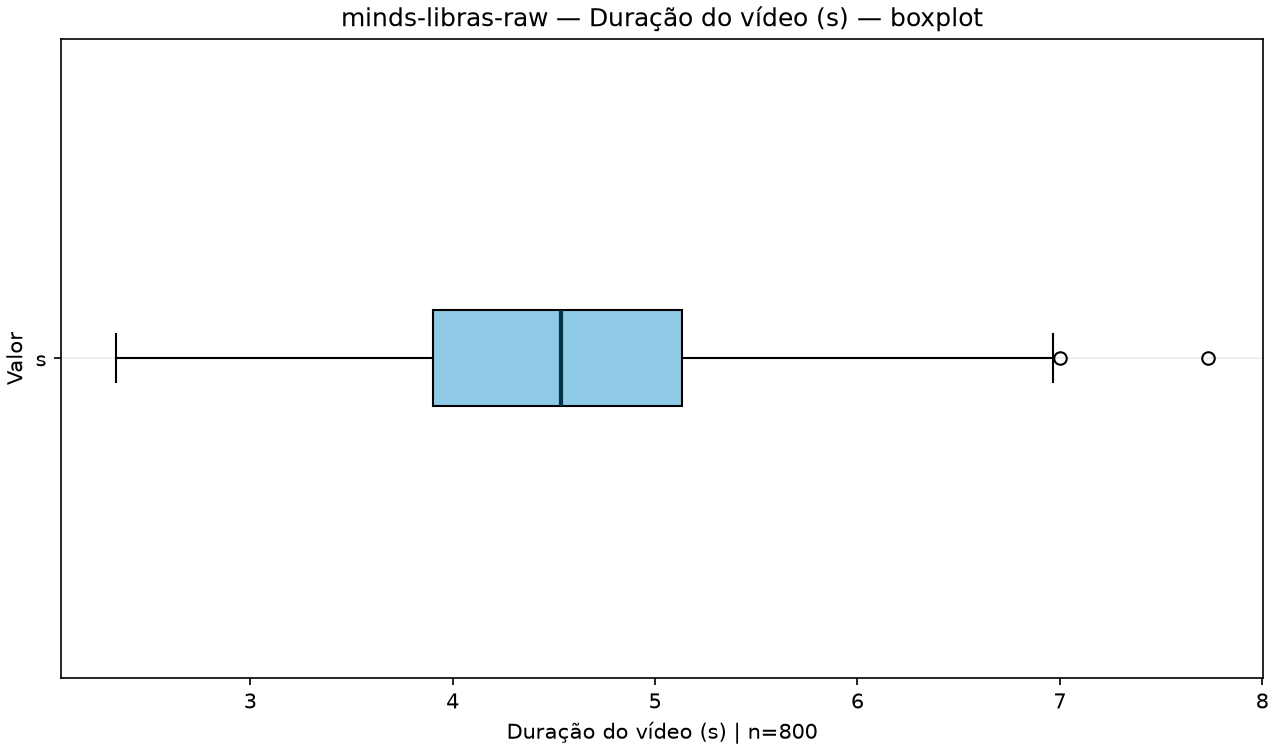

#### minds-libras-raw — actual_duration — ecdf

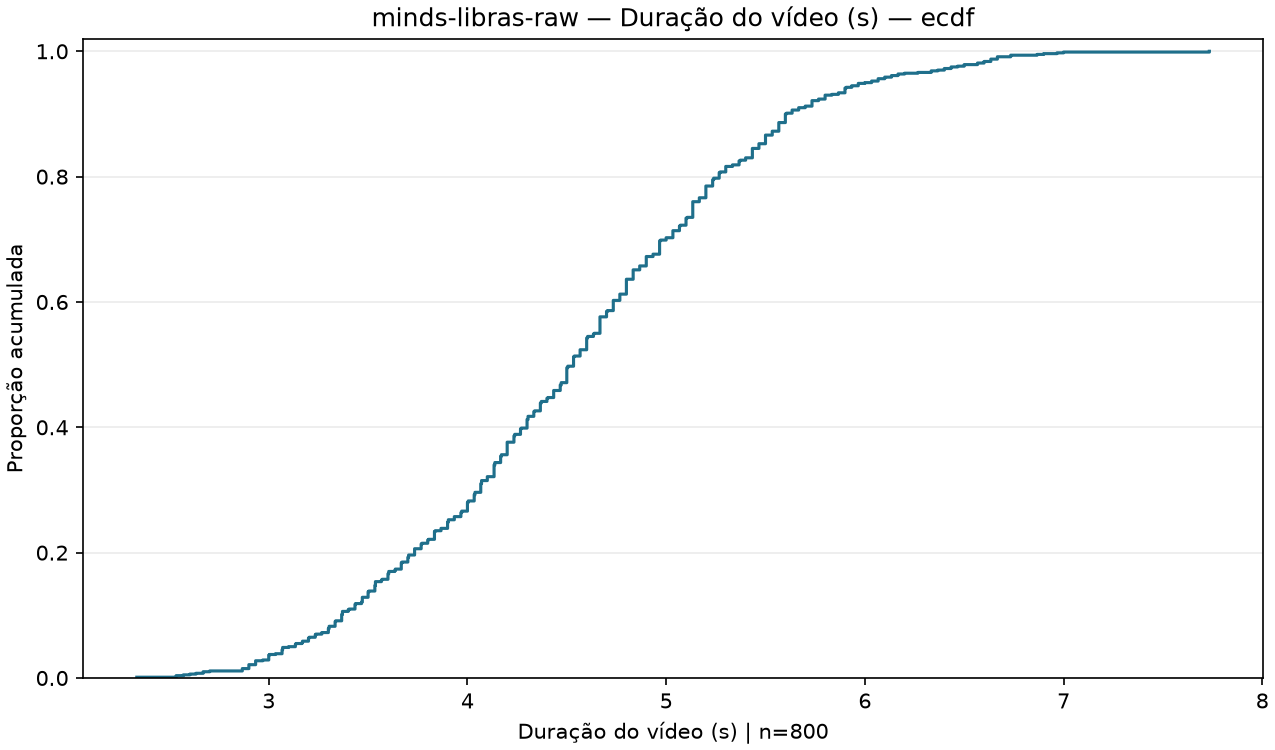

#### minds-libras-raw — actual_duration — histogram

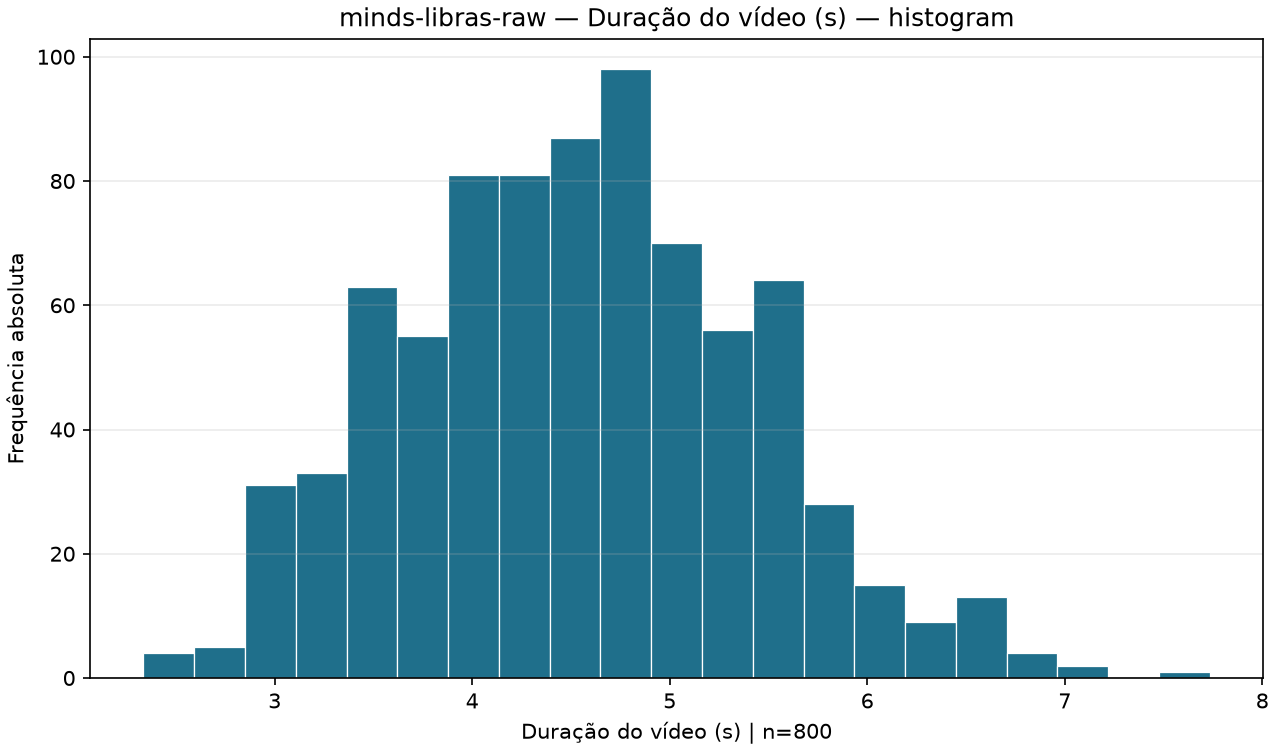

#### minds-libras-raw — actual_fps — boxplot

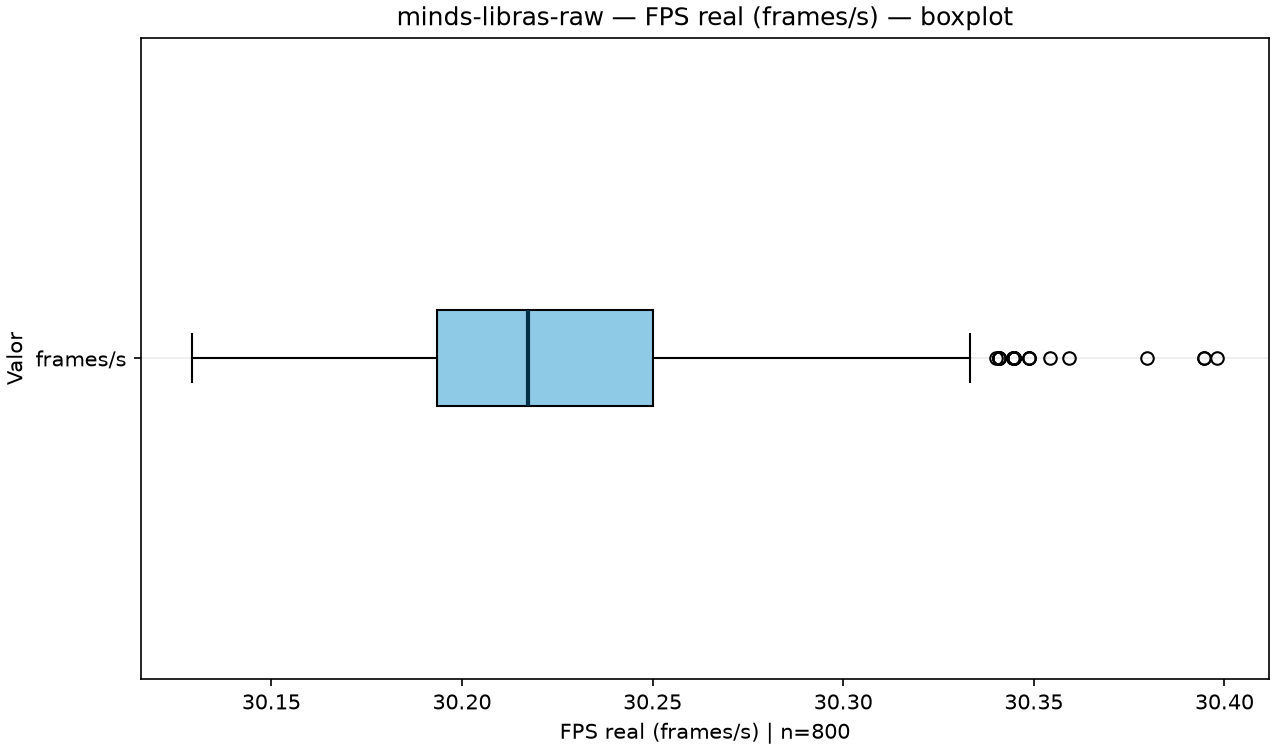

#### minds-libras-raw — actual_fps — ecdf

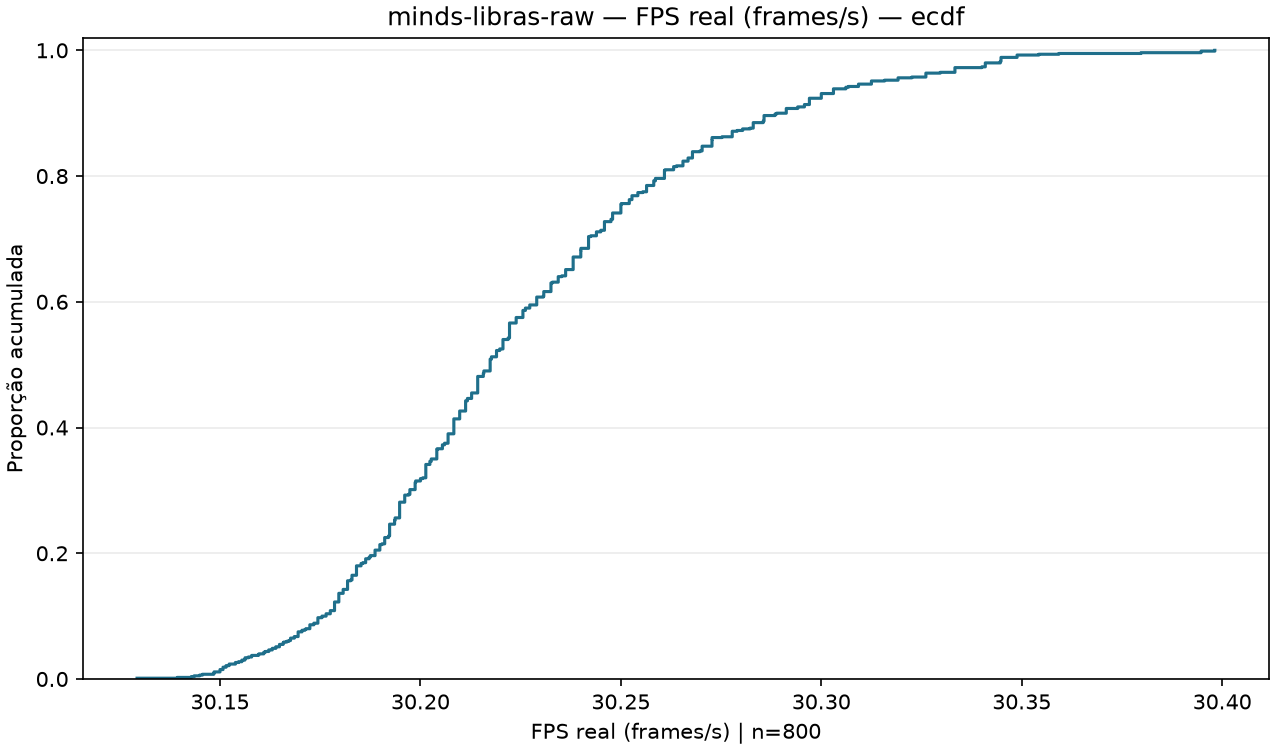

#### minds-libras-raw — actual_fps — histogram

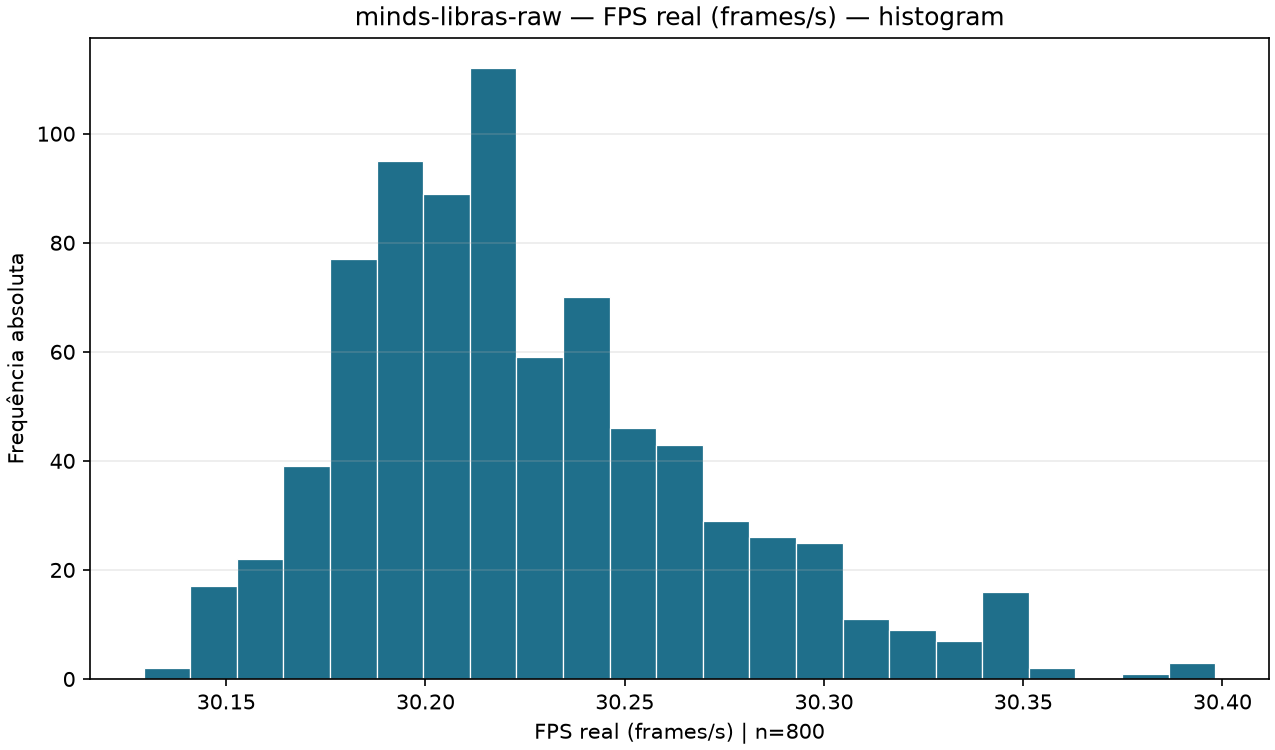

#### minds-libras-raw — actual_frame_count — boxplot

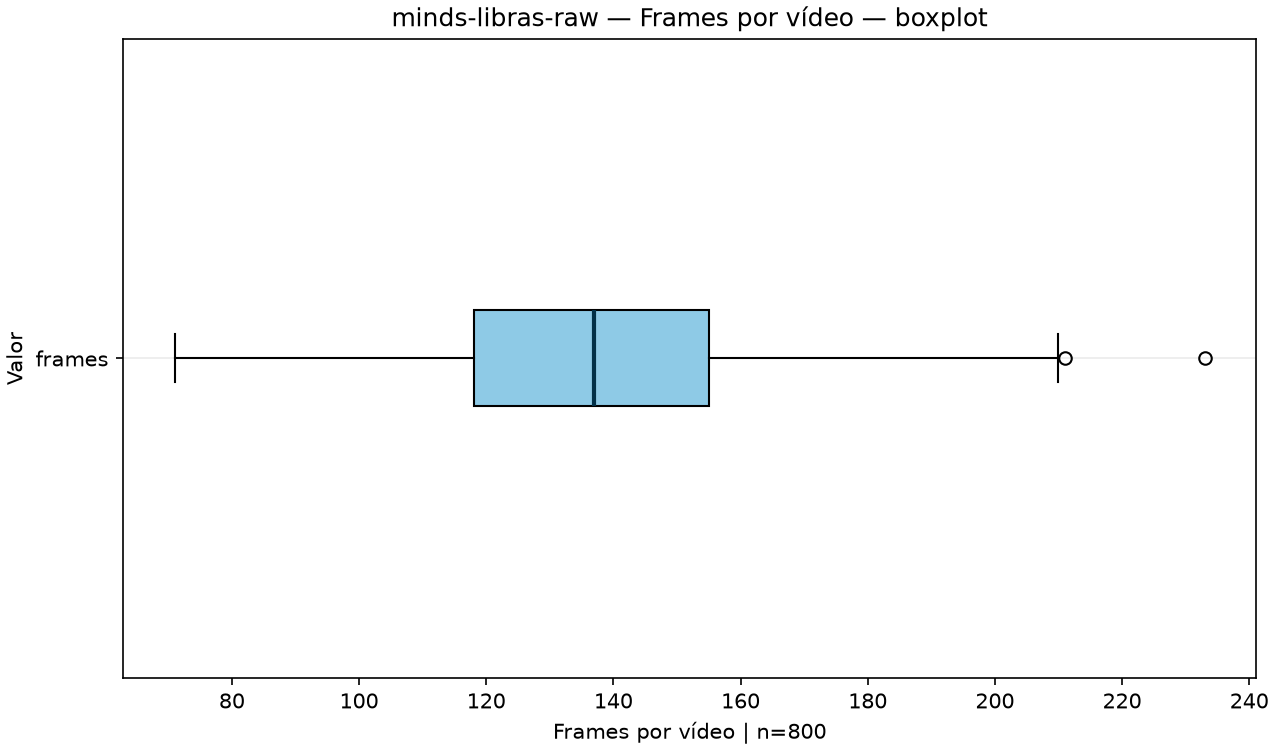

#### minds-libras-raw — actual_frame_count — ecdf

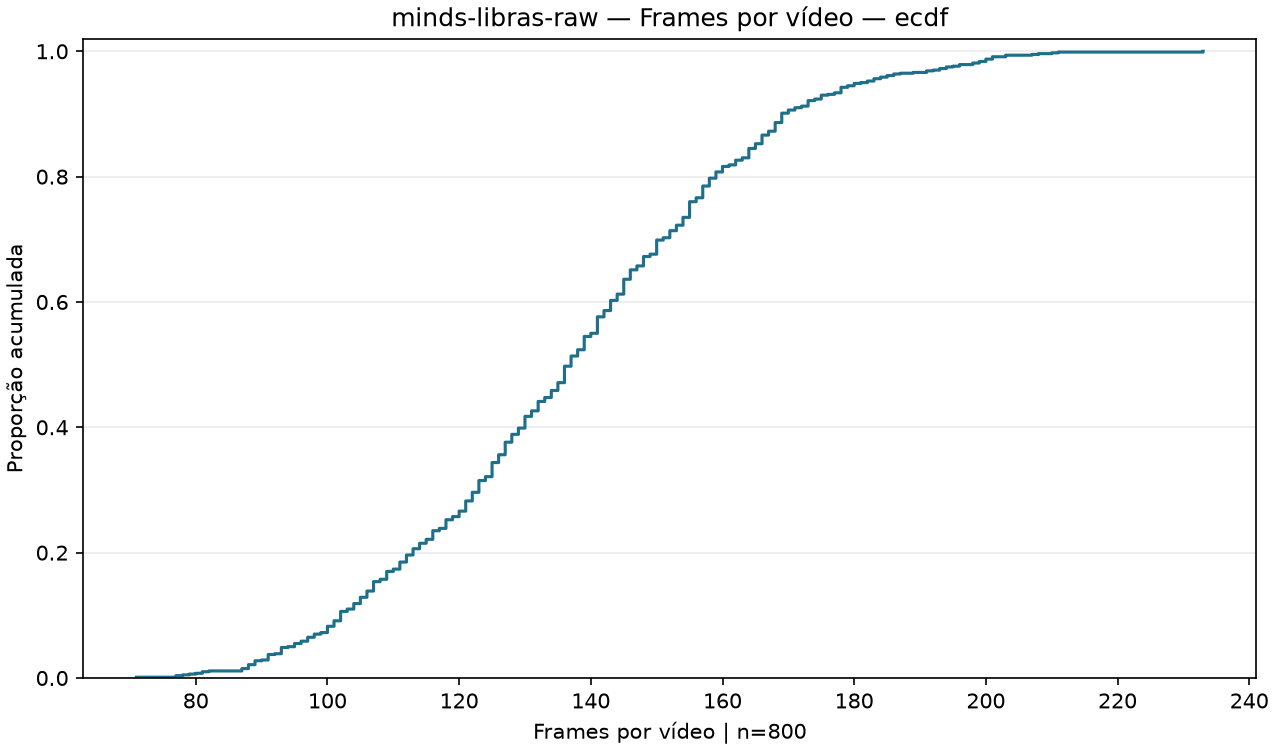

#### minds-libras-raw — actual_frame_count — histogram

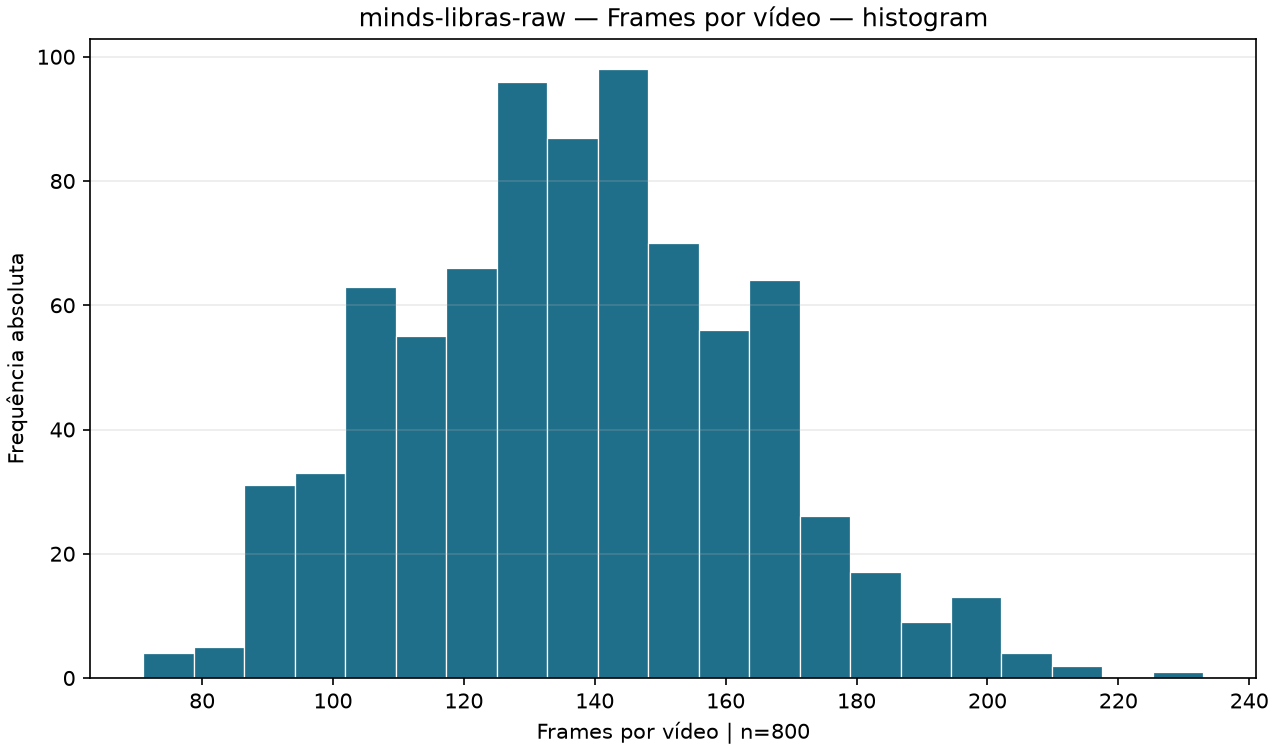

#### v-librasil-raw — actual_duration — boxplot

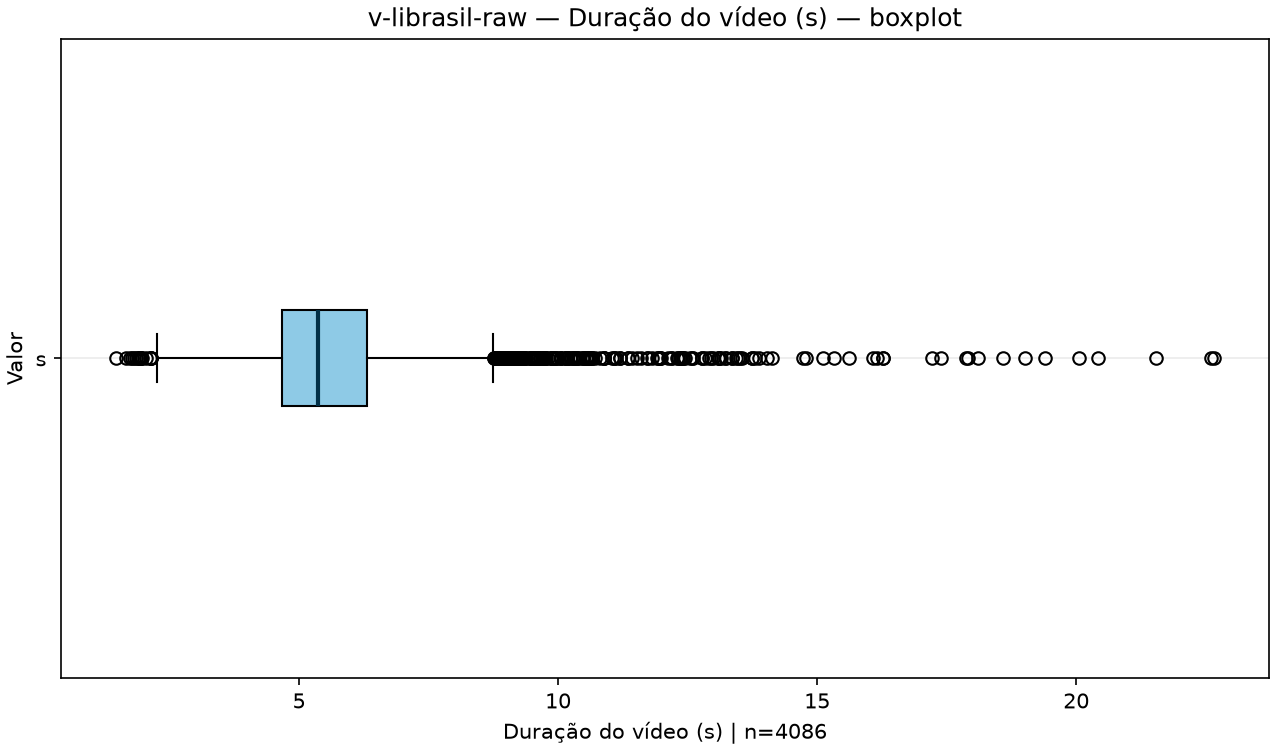

#### v-librasil-raw — actual_duration — ecdf

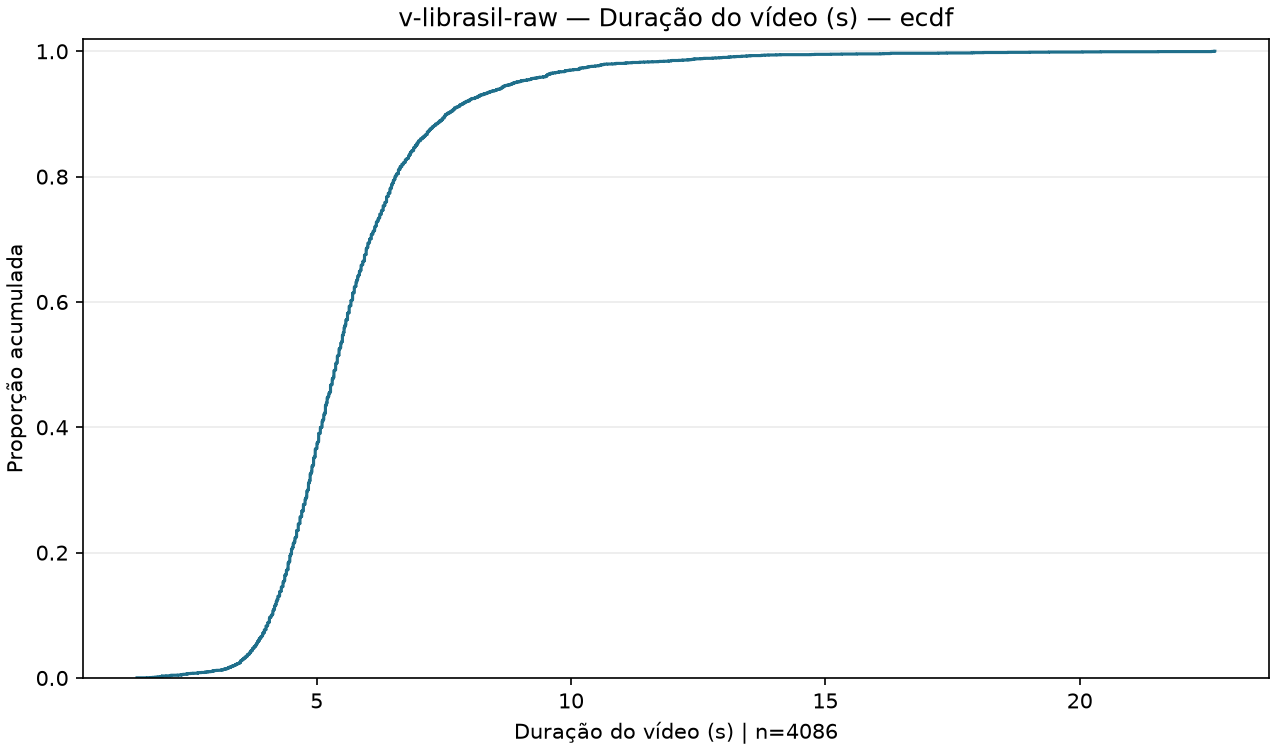

#### v-librasil-raw — actual_duration — histogram

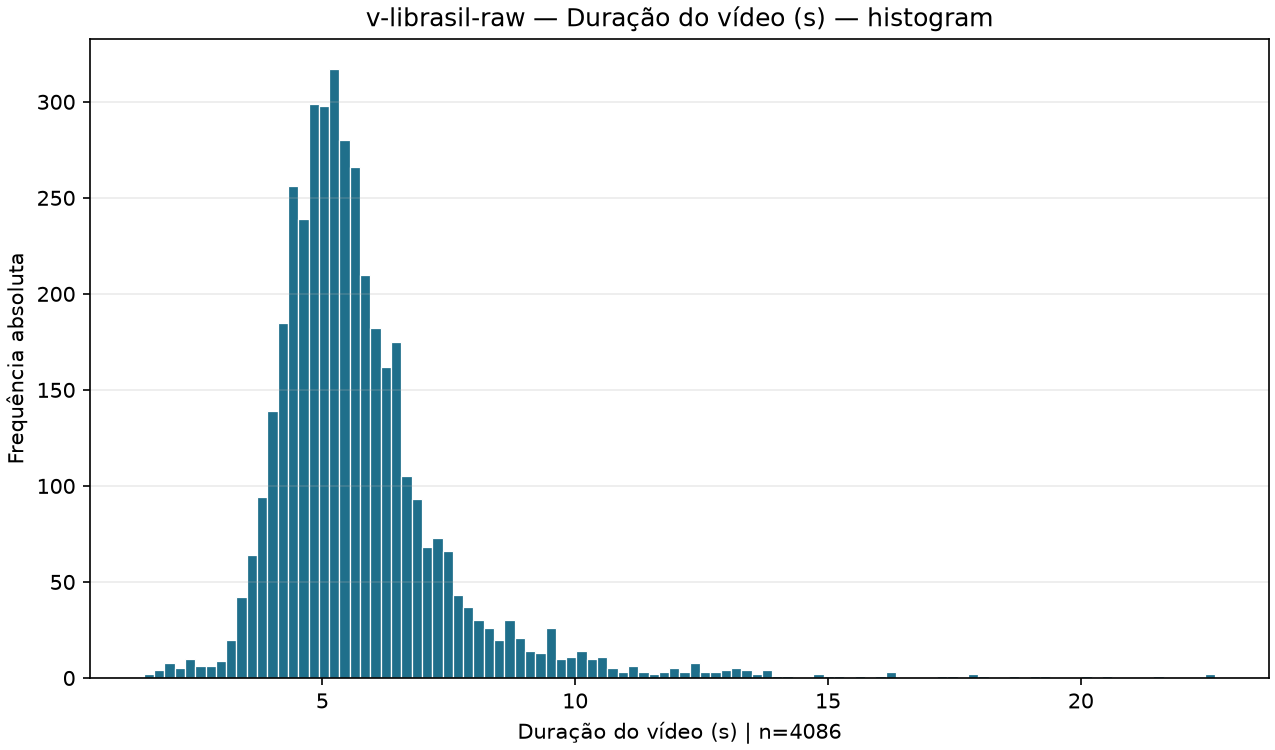

#### v-librasil-raw — actual_fps — boxplot

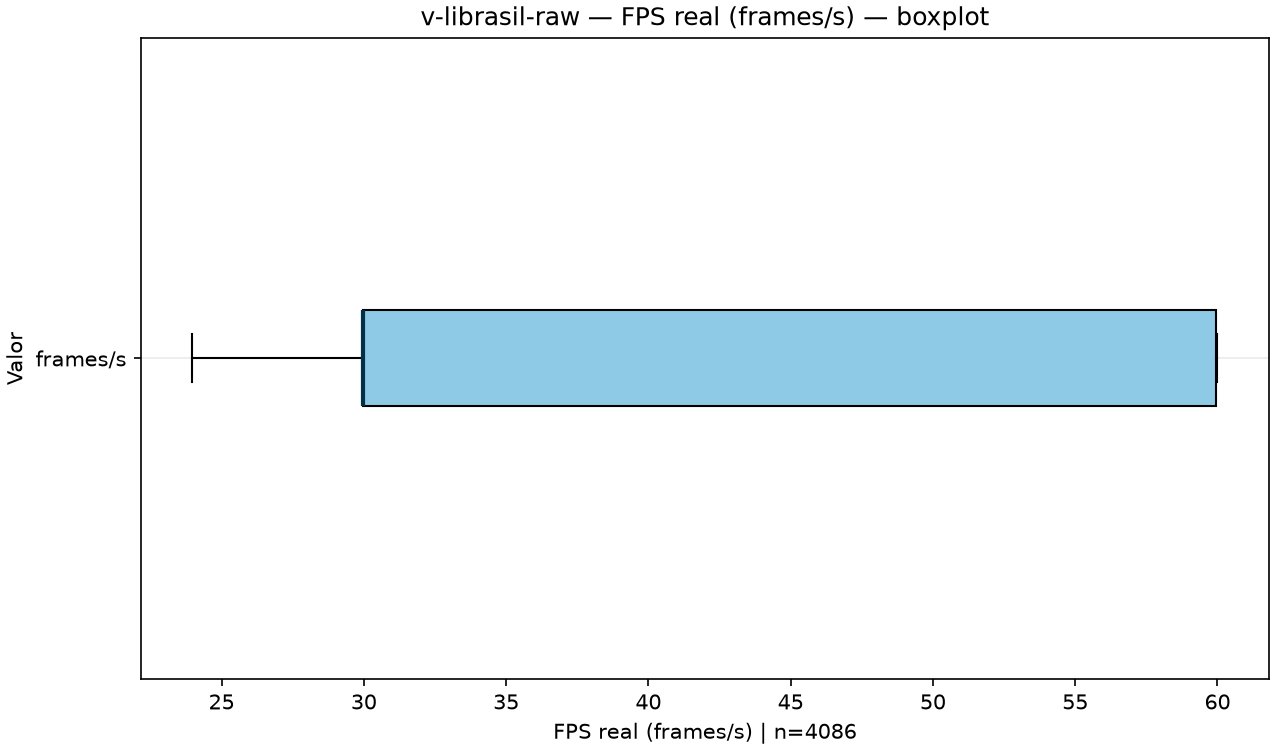

#### v-librasil-raw — actual_fps — ecdf

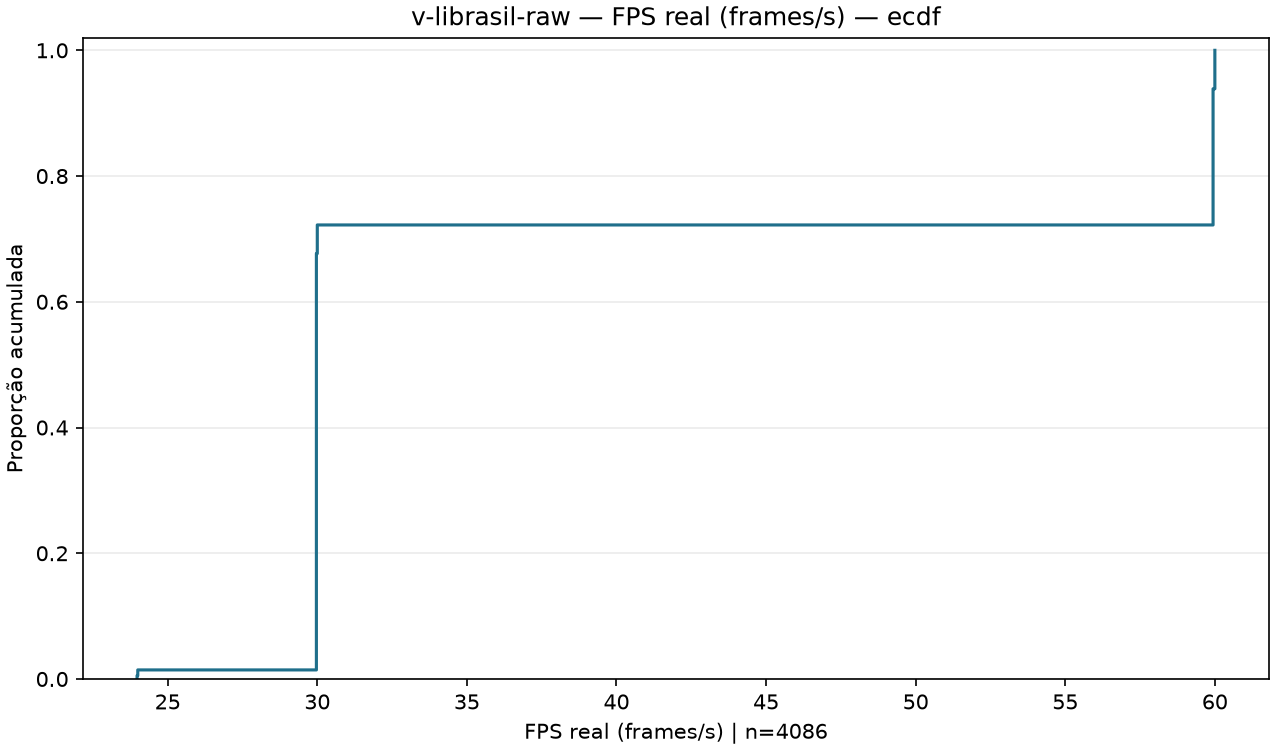

#### v-librasil-raw — actual_fps — histogram

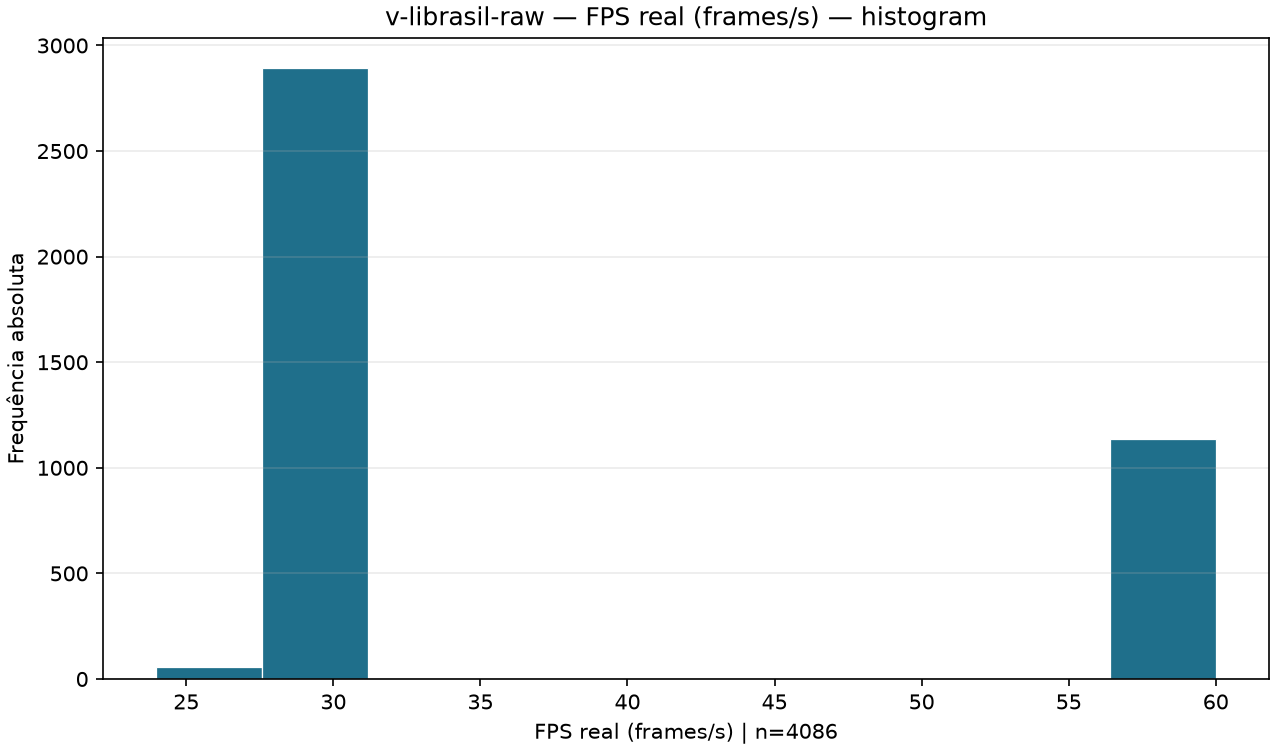

#### v-librasil-raw — actual_frame_count — boxplot

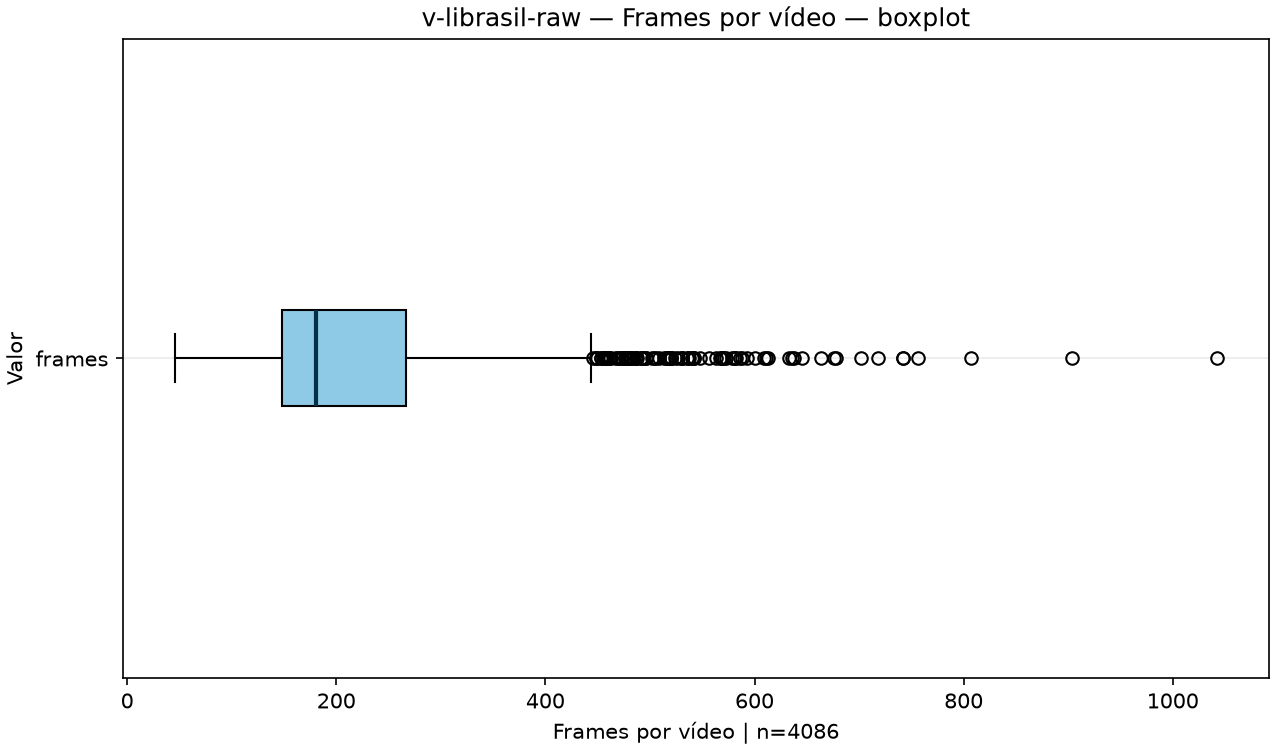

#### v-librasil-raw — actual_frame_count — ecdf

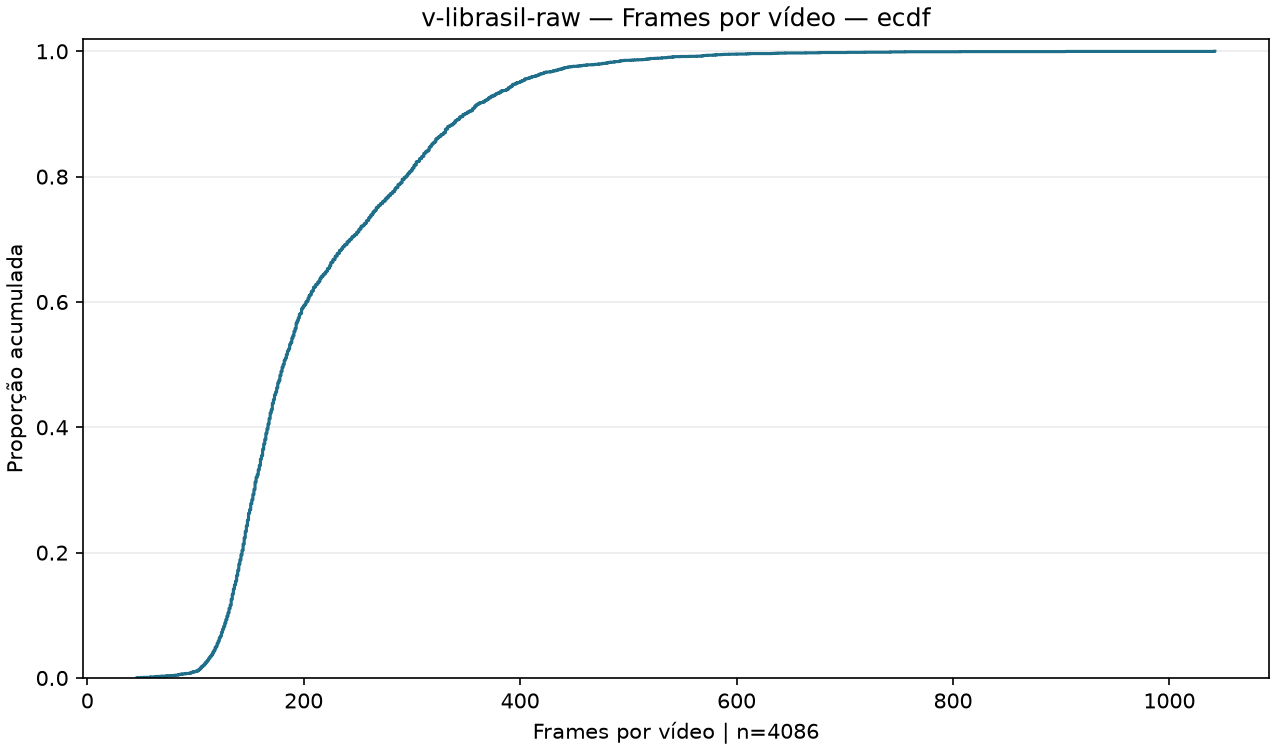

#### v-librasil-raw — actual_frame_count — histogram

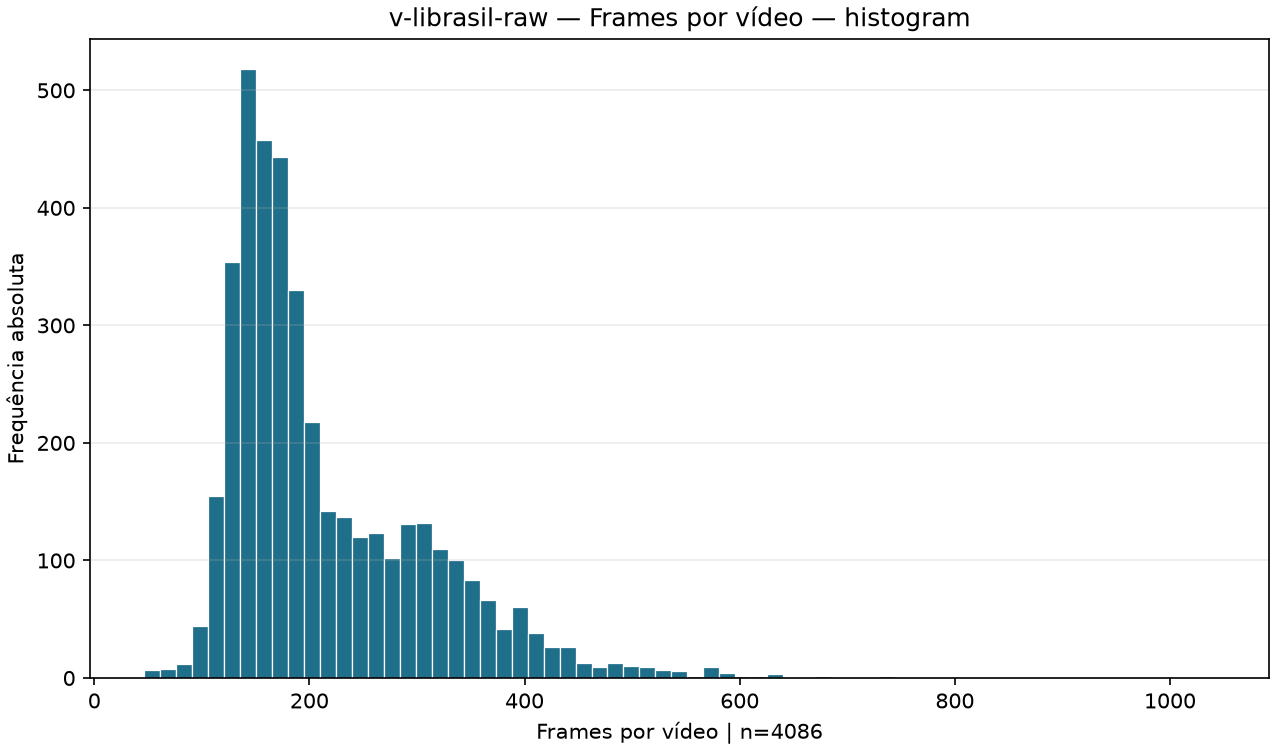

,dataset,variable,figure_type,path,denominator,n,unit,source_scale,histogram_rule,fps_display_note
0,v-librasil-raw,actual_frame_count,histogram,frame_count_distribution/v-librasil-raw__actua...,4086,4086,frames,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
1,v-librasil-raw,actual_frame_count,boxplot,frame_count_distribution/v-librasil-raw__actua...,4086,4086,frames,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
2,v-librasil-raw,actual_frame_count,ecdf,frame_count_distribution/v-librasil-raw__actua...,4086,4086,frames,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
3,v-librasil-raw,actual_duration,histogram,duration_distribution/v-librasil-raw__actual_d...,4086,4086,s,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
4,v-librasil-raw,actual_duration,boxplot,duration_distribution/v-librasil-raw__actual_d...,4086,4086,s,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
5,v-librasil-raw,actual_duration,ecdf,duration_distribution/v-librasil-raw__actual_d...,4086,4086,s,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable
6,v-librasil-raw,actual_fps,histogram,fps_distribution/v-librasil-raw__actual_fps__h...,4086,4086,frames/s,original,Freedman-Diaconis edges; fallback to 10 equal-...,actual_fps remains raw; any displayed tick for...
7,v-librasil-raw,actual_fps,boxplot,fps_distribution/v-librasil-raw__actual_fps__b...,4086,4086,frames/s,original,Freedman-Diaconis edges; fallback to 10 equal-...,actual_fps remains raw; any displayed tick for...
8,v-librasil-raw,actual_fps,ecdf,fps_distribution/v-librasil-raw__actual_fps__e...,4086,4086,frames/s,original,Freedman-Diaconis edges; fallback to 10 equal-...,actual_fps remains raw; any displayed tick for...
9,minds-libras-raw,actual_frame_count,histogram,frame_count_distribution/minds-libras-raw__act...,800,800,frames,original,Freedman-Diaconis edges; fallback to 10 equal-...,not applicable


In [6]:
with TemporaryDirectory(prefix='notebook-part2-figures-') as temporary:
    notebook_figure_root = Path(temporary)
    notebook_figure_metadata = render_temporal_figures(frames, notebook_figure_root)
    for _, figure_row in notebook_figure_metadata.sort_values(['dataset', 'variable', 'figure_type']).iterrows():
        display(Markdown(f"#### {figure_row['dataset']} — {figure_row['variable']} — {figure_row['figure_type']}"))
        display(Image(filename=str(notebook_figure_root / figure_row['path']), width=760))
display(notebook_figure_metadata)

## 7. Validar tabelas, gráficos e entradas

### 7.1 Tabelas

As tabelas recalculadas em memória são comparadas às tabelas publicadas. O objetivo é confirmar que o notebook e a publicação usam a mesma lógica científica.

### 7.2 Gráficos

Os gráficos são renderizados novamente em diretório temporário e seus hashes são comparados aos gráficos publicados. O diretório temporário não é uma fonte de resultados.

### 7.3 Integridade das entradas

Os SHA-256 dos manifests são recalculados após a execução. A comparação deve permanecer idêntica.

In [7]:
published_stats = pd.read_csv(EDA_ROOT / 'tables' / 'temporal_distribution_statistics.csv')
published_percentiles = pd.read_csv(EDA_ROOT / 'tables' / 'temporal_percentiles.csv')
published_candidates = pd.read_csv(EDA_ROOT / 'tables' / 'temporal_extreme_candidates.csv')
published_figure_metadata = pd.read_csv(EDA_ROOT / 'tables' / 'temporal_figure_metadata.csv')

pd.testing.assert_frame_equal(temporal_stats.reset_index(drop=True), published_stats.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(temporal_percentiles.reset_index(drop=True), published_percentiles.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(temporal_candidates.reset_index(drop=True), published_candidates.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(notebook_figure_metadata.reset_index(drop=True), published_figure_metadata.reset_index(drop=True), check_dtype=False)

with TemporaryDirectory(prefix='notebook-part2-hash-') as temporary:
    repeat_root = Path(temporary)
    repeat_metadata = render_temporal_figures(frames, repeat_root)
    pd.testing.assert_frame_equal(repeat_metadata.reset_index(drop=True), published_figure_metadata.reset_index(drop=True), check_dtype=False)
    for relative in current['figures']:
        relative_path = Path(relative)
        published_path = EDA_ROOT / relative_path
        repeated_path = repeat_root / relative_path.relative_to('figures')
        assert sha256_file(published_path) == sha256_file(repeated_path)

for dataset, identity in ((item['dataset'], item) for item in execution['inputs']):
    assert sha256_file(canonical_manifest_path(dataset)) == identity['sha256']
    assert len(frames[dataset]) == identity['row_count']

print('Tabelas publicadas: PASS')
print('Gráficos publicados: PASS')
print('Fingerprints e contagens das entradas: PASS')
print('Exclusões: 0 | Imputações: 0 | ffprobe: não executado')

Tabelas publicadas: PASS
Gráficos publicados: PASS
Fingerprints e contagens das entradas: PASS
Exclusões: 0 | Imputações: 0 | ffprobe: não executado


## 8. Interpretar separadamente por dataset

A interpretação abaixo é carregada do relatório publicado pela execução canônica. Ela foi produzida depois das tabelas e figuras, permanece descritiva e identifica as limitações e o caráter exploratório das observações.

In [8]:
report_text = (EDA_ROOT / 'reports' / 'temporal_distributions.md').read_text(encoding='utf-8')
display(Markdown(report_text))

# Etapa 2 — Parte 2: distribuições temporais

Execução: 20261106T032703445089Z-78a34e7

## Decisão da Parte 2

COMPLETE WITH NOTES — tabelas, figuras e candidatos extremos foram produzidos e validados. A Parte 3 não foi executada.

## Escopo e baseline

A execução usa exclusivamente os manifests Parquet canônicos da Etapa 1, mantendo V-LIBRASIL e MINDS-Libras como populações descritivas separadas. A Parte 1 foi recebida como COMPLETE WITH NOTES.

Cada linha é um vídeo validado. Frames são medidas internas do vídeo e não observações independentes. Não houve leitura ou alteração de data/raw/, execução de ffprobe, imputação, exclusão, transformação dos valores originais, inferência, balanceamento, split ou treinamento.

Contexto preservado da Parte 1: V-LIBRASIL possui 1.364 classes observadas, seis classes com dois sinalizadores e cobertura class × user_id incompleta; MINDS-Libras possui cobertura completa 20 × 8 × 5 = 800.

## Métricas adicionais

- Percentis: P5, P10, Q1, mediana/P50, Q3, P90, P95 e P99, calculados na escala original.
- MAD: mediana de |x - mediana|.
- skewness_fisher_pearson: assimetria descritiva amostral fornecida por pandas.Series.skew(); não é teste inferencial.
- coefficient_of_variation: desvio-padrão com ddof=1 dividido pela média, somente porque todas as médias temporais são positivas.
- Candidatos extremos: valores abaixo de Q1 - 1,5×IQR ou acima de Q3 + 1,5×IQR. Nenhum registro é removido.
- Histogramas usam bordas Freedman–Diaconis; a regra é apenas de visualização. Boxplots exibem os fliers. ECDFs usam os valores ordenados sem suavização.

## Evidência numérica

| dataset          | variable           | unit     | n    | missing_real | mean               | median             | std_ddof_1           | min                | q1                 | q3                | max                | iqr                | mad                  | skewness_fisher_pearson | coefficient_of_variation | below_iqr_lower_fence | above_iqr_upper_fence |
| ---------------- | ------------------ | -------- | ---- | ------------ | ------------------ | ------------------ | -------------------- | ------------------ | ------------------ | ----------------- | ------------------ | ------------------ | -------------------- | ----------------------- | ------------------------ | --------------------- | --------------------- |
| v-librasil-raw   | actual_frame_count | frames   | 4086 | 0            | 216.20582476749877 | 181.0              | 96.43787823122534    | 46.0               | 148.0              | 267.0             | 1042.0             | 119.0              | 43.0                 | 1.665953652358149       | 0.44604662402103057      | 0                     | 102                   |
| v-librasil-raw   | actual_duration    | s        | 4086 | 0            | 5.7249002922173275 | 5.373              | 1.8357092741636418   | 1.469              | 4.671333           | 6.3063            | 22.656             | 1.6349670000000005 | 0.7998329999999996   | 2.73212857940021        | 0.3206534927183244       | 18                    | 221                   |
| v-librasil-raw   | actual_fps         | frames/s | 4086 | 0            | 38.21373633708435  | 29.97002997002997  | 13.502701546552531   | 23.976023976023978 | 29.97002997002997  | 59.94005994005994 | 60.0               | 29.97002997002997  | 0.0                  | 0.9821698133124476      | 0.3533468025069534       | 0                     | 0                     |
| minds-libras-raw | actual_frame_count | frames   | 800  | 0            | 137.06625          | 137.0              | 26.519728145545574   | 71.0               | 118.0              | 155.0             | 233.0              | 37.0               | 18.0                 | 0.21223990244661847     | 0.19348109505837927      | 0                     | 2                     |
| minds-libras-raw | actual_duration    | s        | 800  | 0            | 4.5363637500000005 | 4.534              | 0.8836790847598408   | 2.336              | 3.904              | 5.134             | 7.734              | 1.2300000000000004 | 0.6000000000000005   | 0.21253107324335974     | 0.19479899176071158      | 0                     | 2                     |
| minds-libras-raw | actual_fps         | frames/s | 800  | 0            | 30.22562695767363  | 30.217391304347824 | 0.045479714938958034 | 30.129310344827587 | 30.193548387096776 | 30.25             | 30.398173255316113 | 0.0564516129032242 | 0.027517886626306165 | 0.8378422807737745      | 0.0015046739974209774    | 0                     | 22                    |

## Percentis

| dataset          | variable           | unit     | denominator | n    | missing_real | p05                | p10                | q1                 | median             | q3                | p90                | p95                | p99                |
| ---------------- | ------------------ | -------- | ----------- | ---- | ------------ | ------------------ | ------------------ | ------------------ | ------------------ | ----------------- | ------------------ | ------------------ | ------------------ |
| v-librasil-raw   | actual_frame_count | frames   | 4086        | 4086 | 0            | 119.0              | 130.0              | 148.0              | 181.0              | 267.0             | 349.0              | 398.0              | 535.1500000000001  |
| v-librasil-raw   | actual_duration    | s        | 4086        | 4086 | 0            | 3.7849999999999997 | 4.119              | 4.671333           | 5.373              | 6.3063            | 7.5625             | 8.900500000000001  | 12.954500000000003 |
| v-librasil-raw   | actual_fps         | frames/s | 4086        | 4086 | 0            | 29.97002997002997  | 29.97002997002997  | 29.97002997002997  | 29.97002997002997  | 59.94005994005994 | 59.94005994005994  | 60.0               | 60.0               |
| minds-libras-raw | actual_frame_count | frames   | 800         | 800  | 0            | 94.95              | 102.0              | 118.0              | 137.0              | 155.0             | 169.0              | 181.04999999999995 | 201.0              |
| minds-libras-raw | actual_duration    | s        | 800         | 800  | 0            | 3.1323             | 3.367              | 3.904              | 4.534              | 5.134             | 5.6006             | 6.001699999999999  | 6.667              |
| minds-libras-raw | actual_fps         | frames/s | 800         | 800  | 0            | 30.16393442622951  | 30.176367389060886 | 30.193548387096776 | 30.217391304347824 | 30.25             | 30.289100282076937 | 30.3125            | 30.348837209302324 |

## Observações por dataset e variável

### v-librasil-raw

#### actual_frame_count

Evidência

Denominador=4086; n=4086; missing_real=0; unidade=frames. Candidatos IQR abaixo da cerca inferior: 0; acima da cerca superior: 102.

Observação

Centro: média=216.206, mediana=181. Dispersão: DP=96.4379, IQR=119, MAD=43. skewness=1.66595; assimetria descritiva à direita. a extensão mediana→P95 (217) excede P5→mediana (62). Candidatos pela regra IQR: 102; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: frame_count_distribution/v-librasil-raw__actual_frame_count__histogram.png, frame_count_distribution/v-librasil-raw__actual_frame_count__boxplot.png, frame_count_distribution/v-librasil-raw__actual_frame_count__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 102 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

#### actual_duration

Evidência

Denominador=4086; n=4086; missing_real=0; unidade=s. Candidatos IQR abaixo da cerca inferior: 18; acima da cerca superior: 221.

Observação

Centro: média=5.7249, mediana=5.373. Dispersão: DP=1.83571, IQR=1.63497, MAD=0.799833. skewness=2.73213; assimetria descritiva à direita. a extensão mediana→P95 (3.5275) excede P5→mediana (1.588). Candidatos pela regra IQR: 239; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: duration_distribution/v-librasil-raw__actual_duration__histogram.png, duration_distribution/v-librasil-raw__actual_duration__boxplot.png, duration_distribution/v-librasil-raw__actual_duration__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 239 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

#### actual_fps

Evidência

Denominador=4086; n=4086; missing_real=0; unidade=frames/s. Candidatos IQR abaixo da cerca inferior: 0; acima da cerca superior: 0.

Observação

Centro: média=38.2137, mediana=29.97. Dispersão: DP=13.5027, IQR=29.97, MAD=0. skewness=0.98217; assimetria descritiva à direita. a extensão mediana→P95 (30.03) excede P5→mediana (0). Candidatos pela regra IQR: 0; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: fps_distribution/v-librasil-raw__actual_fps__histogram.png, fps_distribution/v-librasil-raw__actual_fps__boxplot.png, fps_distribution/v-librasil-raw__actual_fps__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 0 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

### minds-libras-raw

#### actual_frame_count

Evidência

Denominador=800; n=800; missing_real=0; unidade=frames. Candidatos IQR abaixo da cerca inferior: 0; acima da cerca superior: 2.

Observação

Centro: média=137.066, mediana=137. Dispersão: DP=26.5197, IQR=37, MAD=18. skewness=0.21224; próxima da simetria pelo limiar exploratório |skewness| < 0,5. a extensão mediana→P95 (44.05) excede P5→mediana (42.05). Candidatos pela regra IQR: 2; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: frame_count_distribution/minds-libras-raw__actual_frame_count__histogram.png, frame_count_distribution/minds-libras-raw__actual_frame_count__boxplot.png, frame_count_distribution/minds-libras-raw__actual_frame_count__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 2 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

#### actual_duration

Evidência

Denominador=800; n=800; missing_real=0; unidade=s. Candidatos IQR abaixo da cerca inferior: 0; acima da cerca superior: 2.

Observação

Centro: média=4.53636, mediana=4.534. Dispersão: DP=0.883679, IQR=1.23, MAD=0.6. skewness=0.212531; próxima da simetria pelo limiar exploratório |skewness| < 0,5. a extensão mediana→P95 (1.4677) excede P5→mediana (1.4017). Candidatos pela regra IQR: 2; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: duration_distribution/minds-libras-raw__actual_duration__histogram.png, duration_distribution/minds-libras-raw__actual_duration__boxplot.png, duration_distribution/minds-libras-raw__actual_duration__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 2 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

#### actual_fps

Evidência

Denominador=800; n=800; missing_real=0; unidade=frames/s. Candidatos IQR abaixo da cerca inferior: 0; acima da cerca superior: 22.

Observação

Centro: média=30.2256, mediana=30.2174. Dispersão: DP=0.0454797, IQR=0.0564516, MAD=0.0275179. skewness=0.837842; assimetria descritiva à direita. a extensão mediana→P95 (0.0951087) excede P5→mediana (0.0534569). Candidatos pela regra IQR: 22; isso é uma flag descritiva, não uma decisão de erro ou exclusão.

Foram publicados 3 gráficos separados: fps_distribution/minds-libras-raw__actual_fps__histogram.png, fps_distribution/minds-libras-raw__actual_fps__boxplot.png, fps_distribution/minds-libras-raw__actual_fps__ecdf.png.

Interpretação

A forma descrita é exploratória e restrita aos vídeos validados deste dataset. A flag IQR identifica uma região extrema da distribuição, mas não estabelece erro de arquivo, erro de anotação ou causa.

Limitação

A tabela completa dos 22 candidatos, quando existentes, está em tables/temporal_extreme_candidates.csv. Não foi aplicado teste de multimodalidade, teste inferencial, inspeção audiovisual ou decisão de exclusão.

## FPS

actual_fps foi preservado integralmente na tabela e nas análises. No MINDS-Libras, os 172 valores exatos continuam sendo variações de avg_frame_rate; não foram convertidos em categorias ou regimes de captura. Formatação de ticks e rótulos é apenas apresentação.

## Candidatos extremos

A tabela temporal_extreme_candidates.csv contém filesystem_key, class, user_id, variável, valor, critério e flag. Nenhum candidato foi excluído ou alterado.

## Proveniência

Run ID: 20261106T032703445089Z-78a34e7
Commit: 78a34e74ccb9d87473d40cb0e5def53e6a97f243

| dataset          | sha256                                                           | size_bytes | row_count |
| ---------------- | ---------------------------------------------------------------- | ---------- | --------- |
| v-librasil-raw   | f0a2259e6094409a59f0f02a77eee478a91967fcc928a6055a5e1e1a33bc9177 | 392028     | 4086      |
| minds-libras-raw | 913c4c185ef4fae21bfded0a78c4c8360a31f2cba51284df45f97aec13596e0a | 44397      | 800       |

As versões das bibliotecas, parâmetros, schema, hashes dos outputs e validações estão em provenance/execution.json.

## Limitações gerais

Esta Parte 2 não faz inferência, não trata frames como observações independentes, não decide qualidade linguística, não identifica causalidade, não cria splits e não decide remoção de outliers. A interpretação de extremos permanece pendente da Parte 6.

## Artefatos

- tables/temporal_distribution_statistics.csv
- tables/temporal_percentiles.csv
- tables/temporal_extreme_candidates.csv
- tables/temporal_figure_metadata.csv
- reports/temporal_distributions.md
- figures/frame_count_distribution/
- figures/duration_distribution/
- figures/fps_distribution/
- provenance/execution.json


## 9. Encerramento da Parte 2

A Parte 2 termina depois da validação da publicação e da reprodução dos outputs. Candidatos extremos permanecem apenas sinalizados para eventual discussão posterior na Parte 6. Nenhuma conclusão de qualidade ou modelagem é tomada aqui.

A Parte 3 — Classes e sinalizadores não é iniciada por este notebook.

In [9]:
final_status = pd.DataFrame([{
    'stage': current['stage'],
    'run_id': current['run_id'],
    'decision': current['decision'],
    'part2_validation': execution['validation']['all_passed'],
    'part3': 'not started',
}])
display(final_status)
assert bool(final_status.loc[0, 'part2_validation']) is True
assert final_status.loc[0, 'part3'] == 'not started'

,stage,run_id,decision,part2_validation,part3
0,stage2_part2_temporal_distributions,20261106T032703445089Z-78a34e7,COMPLETE WITH NOTES,True,not started
